# Notebook 05 — Combined Dengue and Weather Exploratory Data Analysis (EDA)

**Project:** RiskWeave — Climate-informed dengue risk forecasting and inspection planning for Sri Lanka

## Purpose
This notebook explores the existing combined historical dataset before dengue model development. It examines data structure and quality, dengue trends, district differences, seasonality, and associations between dengue cases and weather variables.

**Important:** This notebook does not train prediction models. It does not establish causation. It also does not use future information to create forecasting features.

### Input
`data/processed/dengue_weather_weekly_25_districts.csv`

### Outputs
EDA summary CSV files and charts will be saved under `outputs/eda/`.

### Methodological notes
- Preserve the original combined dataset; do not overwrite it.
- The observation unit is a district × dengue reporting period.
- Reporting periods are not assumed to be Monday–Sunday calendar weeks.
- Ampara/Kalmune aggregation is inherited from the upstream dataset and must be verified as an approved surveillance-area mapping.
- The weather source in the collected data is Open-Meteo ERA5, not NASA POWER. Document this source difference in the project report.
- Associations found here are exploratory, not proof that weather caused dengue cases.


## 1. Import libraries and configure paths

Run this notebook with the project folder as the working directory, or from the `notebooks` folder. The path setup below handles both cases.

In [5]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Detect project root whether Jupyter starts in RiskWeave/ or RiskWeave/notebooks/
cwd = Path.cwd()
if (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not locate the RiskWeave project root. "
        "Start Jupyter from the RiskWeave folder or its notebooks folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "dengue_weather_weekly_25_districts.csv"
EDA_DIR = PROJECT_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Input file:", DATA_PATH)
print("EDA output folder:", EDA_DIR)
print("Input exists:", DATA_PATH.exists())

Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave\notebooks
Input file: c:\Users\Nethmi\Documents\GitHub\RiskWeave\notebooks\data\processed\dengue_weather_weekly_25_districts.csv
EDA output folder: c:\Users\Nethmi\Documents\GitHub\RiskWeave\notebooks\outputs\eda
Input exists: False


## 2. Load the combined dataset

We load the dataset without changing the source file. The original column names are displayed so we can confirm the actual schema before analysis.

In [6]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Get the project root
cwd = Path.cwd()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
elif (cwd / "data").exists():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError("Cannot locate the RiskWeave project folder.")

# Main dataset location
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dengue_weather_weekly_25_districts.csv"
)

# EDA output folder
EDA_DIR = PROJECT_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

print("Current working directory:", cwd)
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())


Current working directory: c:\Users\Nethmi\Documents\GitHub\RiskWeave\notebooks
Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave
Dataset path: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\dengue_weather_weekly_25_districts.csv
Dataset exists: True


## 3. Standardize date types and inspect required columns

This step converts reporting-period dates into pandas datetime values. It does not change the date values themselves.

The combined dataset is expected to contain `area`, `week_start`, `week_end`, and `dengue_cases`. If your file uses different names, stop and inspect the column list rather than silently renaming columns.

In [8]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (24775, 27)
Columns: ['district_key', 'week_start', 'week_end', 'dengue_cases', 'reporting_period_days', 'source_reporting_rows', 'source_areas', 'weather_days_observed', 'weather_days_expected', 'weather_days_complete', 'precipitation_sum', 'precipitation_hours', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'precipitation_mean_daily', 'shortwave_radiation_mean_daily', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'cloud_cover_mean', 'wind_direction_10m_dominant']


,district_key,week_start,week_end,dengue_cases,reporting_period_days,source_reporting_rows,source_areas,weather_days_observed,weather_days_expected,weather_days_complete,...,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,cloud_cover_mean,wind_direction_10m_dominant
0,ampara,2006-12-23,2006-12-29,0,7,2,Ampara | Kalmune,7,7,True,...,27.528571,23.571429,79.857143,87.285714,70.571429,21.471429,15.685714,21.085714,89.142857,8.574025
1,ampara,2006-12-30,2007-01-05,0,7,2,Ampara | Kalmune,7,7,True,...,28.042857,21.385714,71.142857,82.428571,57.000000,18.885714,14.485714,19.614286,59.428571,358.285579
2,ampara,2007-01-06,2007-01-12,0,7,2,Ampara | Kalmune,7,7,True,...,26.957143,23.271429,86.285714,92.285714,78.714286,22.285714,14.842857,18.828571,78.285714,20.694632
3,ampara,2007-01-13,2007-01-19,0,7,2,Ampara | Kalmune,7,7,True,...,27.728571,23.571429,83.142857,89.714286,74.571429,22.357143,17.114286,23.000000,77.857143,11.275426
4,ampara,2007-01-20,2007-01-26,0,7,2,Ampara | Kalmune,7,7,True,...,27.814286,22.742857,76.714286,85.142857,66.142857,20.600000,15.514286,20.385714,71.142857,7.286656


In [10]:

# Required columns in our actual dataset
required_cols = [
    "district_key",
    "week_start",
    "week_end",
    "dengue_cases"
]

missing_required = [
    col for col in required_cols
    if col not in df.columns
]

if missing_required:
    raise ValueError(f"Missing columns: {missing_required}")

# Convert data types
df["week_start"] = pd.to_datetime(
    df["week_start"], errors="coerce"
)

df["week_end"] = pd.to_datetime(
    df["week_end"], errors="coerce"
)

df["dengue_cases"] = pd.to_numeric(
    df["dengue_cases"], errors="coerce"
)

# Display dataset information
print("Date range:",
      df["week_start"].min(),
      "to",
      df["week_end"].max())

print("Number of reporting areas:",
      df["district_key"].nunique())

print("Reporting areas:",
      sorted(df["district_key"].dropna().unique()))

print("Reporting periods:",
      df[["week_start", "week_end"]]
      .drop_duplicates().shape[0])

display(df[required_cols].head())


Date range: 2006-12-23 00:00:00 to 2025-12-19 00:00:00
Number of reporting areas: 25
Reporting areas: ['ampara', 'anuradhapura', 'badulla', 'batticaloa', 'colombo', 'galle', 'gampaha', 'hambantota', 'jaffna', 'kalutara', 'kandy', 'kegalle', 'kilinochchi', 'kurunegala', 'mannar', 'matale', 'matara', 'moneragala', 'mullaitivu', 'nuwaraeliya', 'polonnaruwa', 'puttalam', 'ratnapura', 'trincomalee', 'vavuniya']
Reporting periods: 991


,district_key,week_start,week_end,dengue_cases
0,ampara,2006-12-23,2006-12-29,0
1,ampara,2006-12-30,2007-01-05,0
2,ampara,2007-01-06,2007-01-12,0
3,ampara,2007-01-13,2007-01-19,0
4,ampara,2007-01-20,2007-01-26,0


## 4. Data quality checks

We check missing values, duplicate district-period keys, invalid date intervals, negative case counts, and reporting-period lengths.

A flagged row is investigated; it is not automatically deleted.

In [12]:

# Use the actual district column name
key_cols = ["district_key", "week_start", "week_end"]

quality_summary = pd.DataFrame({
    "check": [
        "Total rows",
        "Total columns",
        "Missing district keys",
        "Missing week_start",
        "Missing week_end",
        "Missing dengue cases",
        "Duplicate district-reporting-period keys",
        "Invalid date intervals",
        "Negative dengue case values",
    ],
    "value": [
        len(df),
        len(df.columns),
        int(df["district_key"].isna().sum()),
        int(df["week_start"].isna().sum()),
        int(df["week_end"].isna().sum()),
        int(df["dengue_cases"].isna().sum()),
        int(df.duplicated(key_cols).sum()),
        int((df["week_end"] < df["week_start"]).sum()),
        int((df["dengue_cases"] < 0).sum()),
    ]
})

print("DATA QUALITY SUMMARY")
display(quality_summary)

# Save quality results
quality_summary.to_csv(
    EDA_DIR / "eda_data_quality_summary.csv",
    index=False
)

# Check reporting period lengths
df["reporting_period_days_check"] = (
    df["week_end"] - df["week_start"]
).dt.days + 1

period_length_summary = (
    df["reporting_period_days_check"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("reporting_period_days")
    .reset_index(name="row_count")
)

print("REPORTING PERIOD LENGTHS")
display(period_length_summary)

period_length_summary.to_csv(
    EDA_DIR / "eda_reporting_period_lengths.csv",
    index=False
)


DATA QUALITY SUMMARY


,check,value
0,Total rows,24775
1,Total columns,27
2,Missing district keys,0
3,Missing week_start,0
4,Missing week_end,0
5,Missing dengue cases,0
6,Duplicate district-reporting-period keys,0
7,Invalid date intervals,0
8,Negative dengue case values,0


REPORTING PERIOD LENGTHS


,reporting_period_days,row_count
0,6,25
1,7,24725
2,8,25


## 5. Dengue cases: overall distribution

Dengue case counts are count data and may be highly skewed. We inspect summary statistics and a histogram. The histogram is descriptive only; it does not determine a model family by itself.

count    24775.000000
mean        32.414692
std         80.695209
min          0.000000
25%          2.000000
50%         10.000000
75%         30.000000
90%         76.000000
95%        134.000000
99%        344.260000
max       2631.000000
Name: dengue_cases, dtype: float64

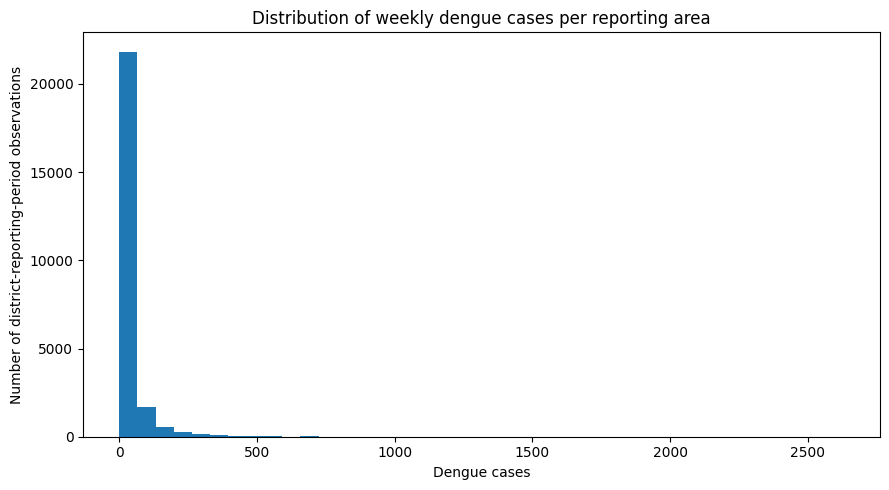

In [13]:
display(df["dengue_cases"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

fig, ax = plt.subplots(figsize=(9, 5))
valid_cases = df["dengue_cases"].dropna()
ax.hist(valid_cases, bins=40)
ax.set_title("Distribution of weekly dengue cases per reporting area")
ax.set_xlabel("Dengue cases")
ax.set_ylabel("Number of district-reporting-period observations")
fig.tight_layout()
fig.savefig(EDA_DIR / "dengue_cases_distribution.png", dpi=150)
plt.show()

## 6. Weekly dengue trends over time

The dataset is district-level. To show the national total per reporting period, we sum cases across the included reporting areas for each exact `week_start` and `week_end`.

**Caution:** This is the sum of the 25 reporting areas represented in the processed dataset. It should not be described as an independently verified national total until the Ampara/Kalmune reporting-area mapping is confirmed.

,week_start,week_end,total_dengue_cases
0,2006-12-23,2006-12-29,167
1,2006-12-30,2007-01-05,181
2,2007-01-06,2007-01-12,163
3,2007-01-13,2007-01-19,131
4,2007-01-20,2007-01-26,144


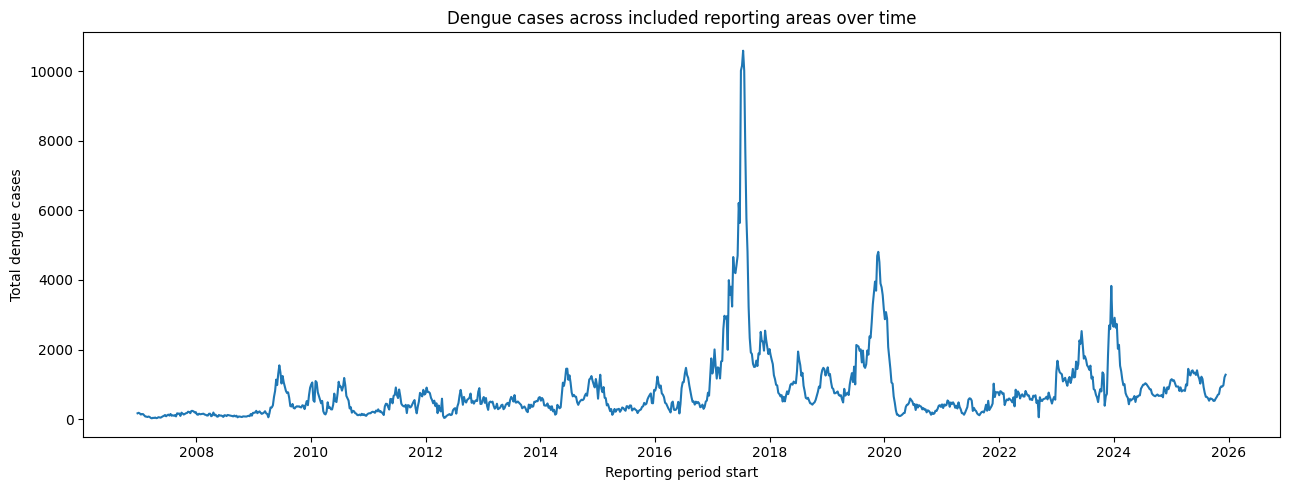

In [14]:
national_period = (
    df.groupby(["week_start", "week_end"], as_index=False)
      .agg(total_dengue_cases=("dengue_cases", "sum"))
      .sort_values("week_start")
)

display(national_period.head())
national_period.to_csv(EDA_DIR / "eda_total_dengue_by_reporting_period.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(national_period["week_start"], national_period["total_dengue_cases"])
ax.set_title("Dengue cases across included reporting areas over time")
ax.set_xlabel("Reporting period start")
ax.set_ylabel("Total dengue cases")
fig.tight_layout()
fig.savefig(EDA_DIR / "dengue_overall_time_trend.png", dpi=150)
plt.show()

## 7. District-level dengue comparison

We compare total, mean, median, maximum and variability of weekly cases by reporting area. High totals can reflect population size as well as disease burden; these summaries are not population-adjusted incidence rates.

DISTRICT-LEVEL DENGUE SUMMARY


,district_key,total_cases,mean_weekly_cases,median_weekly_cases,maximum_weekly_cases,standard_deviation,reporting_periods
4,colombo,174701,176.287588,126.0,1972,202.967592,991
6,gampaha,102397,103.326942,55.0,2631,192.109996,991
10,kandy,66537,67.141271,38.0,1062,102.342810,991
9,kalutara,48564,49.005045,31.0,703,68.334405,991
8,jaffna,44908,45.315843,18.0,931,91.300393,991
13,kurunegala,41664,42.042381,25.0,681,62.356633,991
22,ratnapura,39364,39.721493,25.0,920,63.148623,991
11,kegalle,34141,34.451060,20.0,807,62.420902,991
3,batticaloa,33125,33.425832,15.0,384,51.238443,991
5,galle,31156,31.438951,17.0,332,43.904350,991


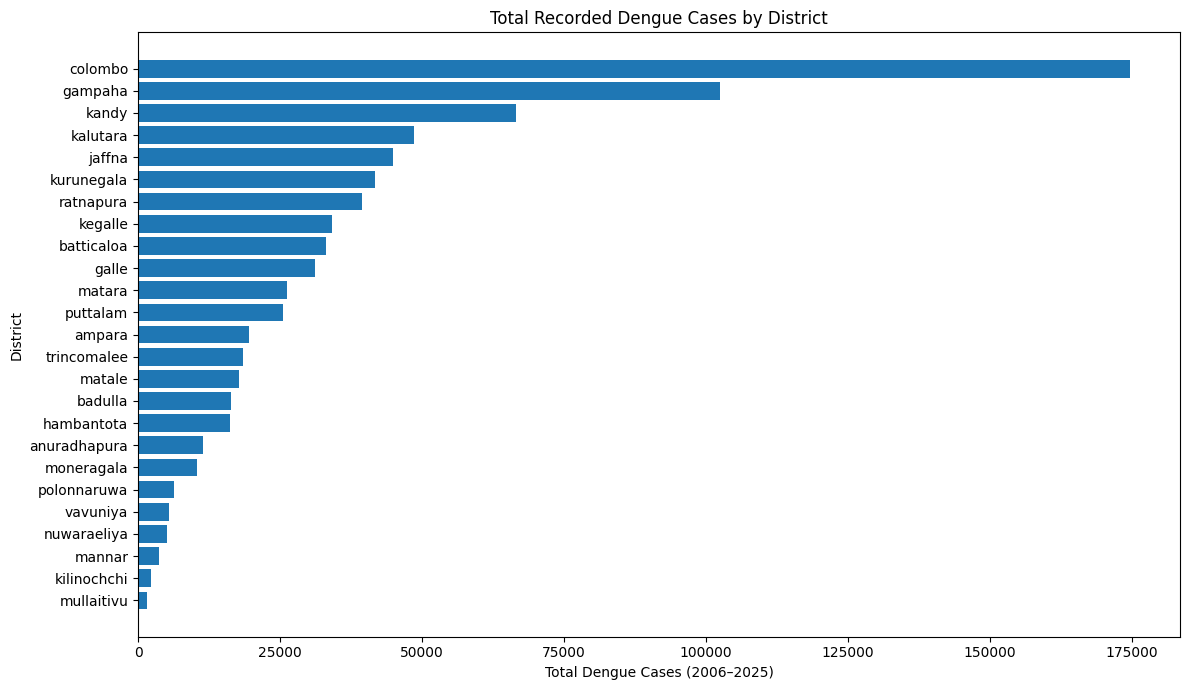

In [16]:

district_summary = (
    df.groupby("district_key")["dengue_cases"]
      .agg(
          total_cases="sum",
          mean_weekly_cases="mean",
          median_weekly_cases="median",
          maximum_weekly_cases="max",
          standard_deviation="std",
          reporting_periods="count"
      )
      .reset_index()
      .sort_values("total_cases", ascending=False)
)

print("DISTRICT-LEVEL DENGUE SUMMARY")
display(district_summary)

# Save summary
district_summary.to_csv(
    EDA_DIR / "eda_district_dengue_summary.csv",
    index=False
)

# Plot total dengue cases
fig, ax = plt.subplots(figsize=(12, 7))

plot_data = district_summary.sort_values("total_cases")

ax.barh(
    plot_data["district_key"],
    plot_data["total_cases"]
)

ax.set_title("Total Recorded Dengue Cases by District")
ax.set_xlabel("Total Dengue Cases (2006–2025)")
ax.set_ylabel("District")

fig.tight_layout()

fig.savefig(
    EDA_DIR / "dengue_total_by_area.png",
    dpi=150
)

plt.show()


## 8. Seasonal patterns

We calculate the calendar month from each reporting period's start date and summarize dengue cases by month. Because reporting periods can cross month boundaries, this is an approximate seasonal description based on `week_start`, not a day-weighted monthly case allocation.

For formal seasonal modelling, we will use carefully defined week-of-year or cyclic time features and preserve chronological validation.

,start_month,mean_cases,median_cases,total_cases,observations
0,1,37.973012,14.0,78794,2075
1,2,27.887273,12.0,53683,1925
2,3,21.709176,8.0,46132,2125
3,4,24.539259,7.0,49692,2025
4,5,28.980476,7.0,60859,2100
5,6,39.797561,11.0,81585,2050
6,7,54.667470,13.0,113435,2075
7,8,30.600471,8.0,65026,2125
8,9,21.937284,8.0,44423,2025
9,10,24.725238,7.0,51923,2100


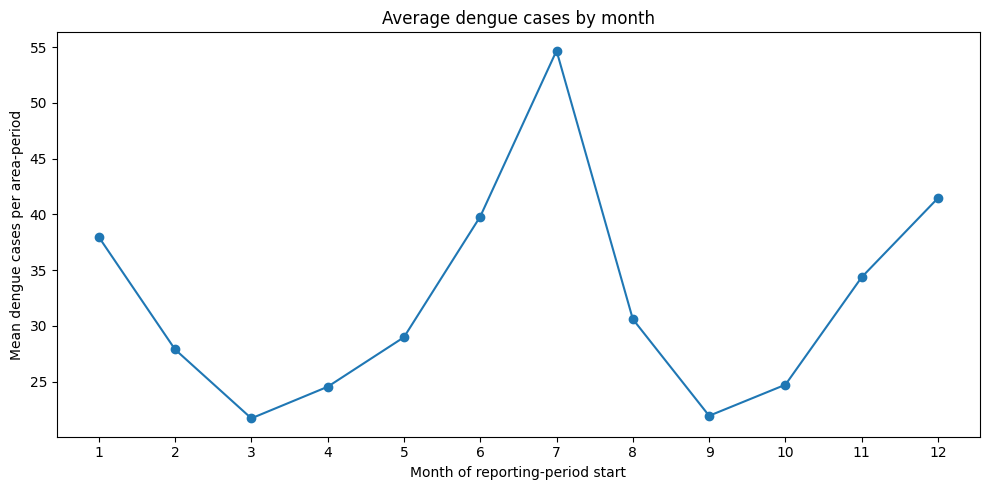

In [17]:
df["start_month"] = df["week_start"].dt.month
df["start_year"] = df["week_start"].dt.year

monthly_seasonality = (
    df.groupby("start_month")["dengue_cases"]
      .agg(
          mean_cases="mean",
          median_cases="median",
          total_cases="sum",
          observations="count"
      )
      .reindex(range(1, 13))
      .reset_index()
)

display(monthly_seasonality)
monthly_seasonality.to_csv(EDA_DIR / "eda_dengue_by_start_month.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_seasonality["start_month"], monthly_seasonality["mean_cases"], marker="o")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month of reporting-period start")
ax.set_ylabel("Mean dengue cases per area-period")
ax.set_title("Average dengue cases by month")
fig.tight_layout()
fig.savefig(EDA_DIR / "dengue_monthly_seasonality.png", dpi=150)
plt.show()

## 9. Yearly dengue patterns

This summarizes the annual number of recorded cases across the included reporting areas. The source ends in December 2025, so the final year may cover only part of a calendar year depending on the exact source coverage.

,start_year,total_cases,mean_cases_per_area_period,reporting_area_periods
0,2006,348,6.960000,50
1,2007,6038,4.644615,1300
2,2008,5515,4.242308,1300
3,2009,26552,20.424615,1300
4,2010,25006,19.235385,1300
5,2011,22381,16.891321,1325
6,2012,23342,17.955385,1300
7,2013,22472,17.286154,1300
8,2014,35650,27.423077,1300
9,2015,22180,17.061538,1300


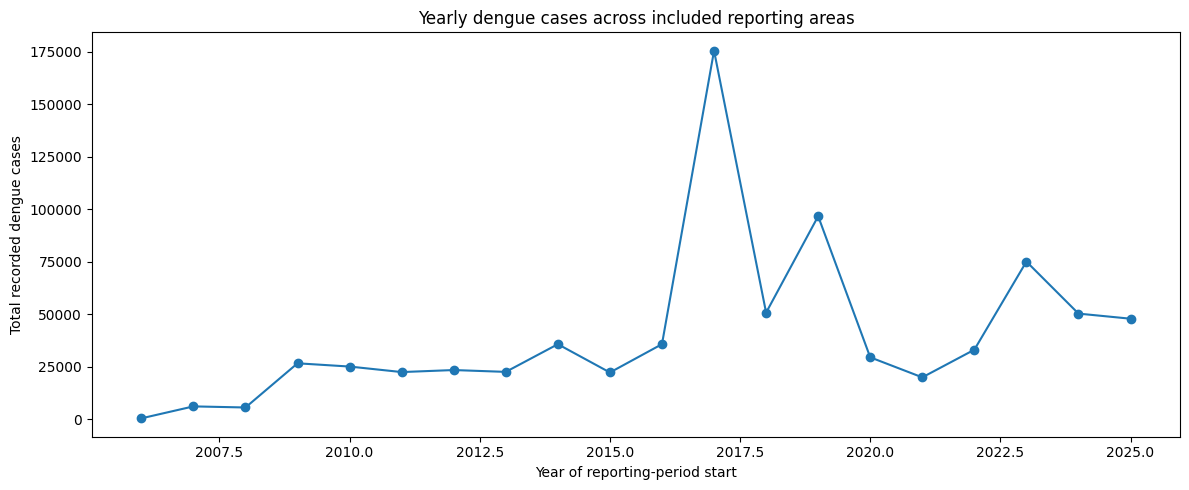

In [18]:
yearly_summary = (
    df.groupby("start_year")["dengue_cases"]
      .agg(
          total_cases="sum",
          mean_cases_per_area_period="mean",
          reporting_area_periods="count"
      )
      .reset_index()
)

display(yearly_summary)
yearly_summary.to_csv(EDA_DIR / "eda_dengue_by_year.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(yearly_summary["start_year"], yearly_summary["total_cases"], marker="o")
ax.set_xlabel("Year of reporting-period start")
ax.set_ylabel("Total recorded dengue cases")
ax.set_title("Yearly dengue cases across included reporting areas")
fig.tight_layout()
fig.savefig(EDA_DIR / "dengue_yearly_trend.png", dpi=150)
plt.show()

## 10. Weather variables available for analysis

We identify numeric weather columns from the combined dataset. The notebook prints the candidates so that we can inspect the actual schema and avoid assuming a column exists.

We exclude identifiers, dates, dengue target, and helper fields from the weather-variable list.

In [19]:
exclude_from_weather = {
    "dengue_cases",
    "year",
    "week",
    "start_month",
    "start_year",
    "reporting_period_days_check",
}

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
weather_numeric_cols = [
    col for col in numeric_cols
    if col not in exclude_from_weather
    and not col.lower().endswith("_cases")
]

print("Numeric columns:", numeric_cols)
print("\nCandidate numeric weather/features:")
print(weather_numeric_cols)

display(df[weather_numeric_cols].describe().T if weather_numeric_cols else
        pd.DataFrame({"message": ["No numeric weather columns were detected."]}))

Numeric columns: ['dengue_cases', 'reporting_period_days', 'source_reporting_rows', 'weather_days_observed', 'weather_days_expected', 'precipitation_sum', 'precipitation_hours', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'precipitation_mean_daily', 'shortwave_radiation_mean_daily', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'cloud_cover_mean', 'wind_direction_10m_dominant', 'reporting_period_days_check', 'start_month', 'start_year']

Candidate numeric weather/features:
['reporting_period_days', 'source_reporting_rows', 'weather_days_observed', 'weather_days_expected', 'precipitation_sum', 'precipitation_hours', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'precipitation_mean_daily', 'shortwave_radiation_mean_daily', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relat

,count,mean,std,min,25%,50%,75%,max
reporting_period_days,24775.0,7.000000,0.044925,6.000000,7.000000,7.000000,7.000000,8.000000
source_reporting_rows,24775.0,1.040000,0.195963,1.000000,1.000000,1.000000,1.000000,2.000000
weather_days_observed,24775.0,7.000000,0.044925,6.000000,7.000000,7.000000,7.000000,8.000000
weather_days_expected,24775.0,7.000000,0.044925,6.000000,7.000000,7.000000,7.000000,8.000000
precipitation_sum,24775.0,37.582490,47.456314,0.000000,6.000000,21.000000,52.800000,592.200000
precipitation_hours,24775.0,50.274228,40.293566,0.000000,16.000000,40.000000,77.000000,168.000000
shortwave_radiation_sum,24775.0,131.448515,24.755396,25.190000,116.700000,134.550000,149.710000,197.910000
et0_fao_evapotranspiration,24775.0,29.141592,7.517870,5.560000,23.770000,28.610000,34.350000,54.660000
precipitation_mean_daily,24775.0,5.369492,6.780325,0.000000,0.857143,3.000000,7.542857,84.600000
shortwave_radiation_mean_daily,24775.0,18.777754,3.530520,3.598571,16.676429,19.227143,21.385714,26.817143


## 11. Exploratory correlations between dengue and weather

We calculate Pearson and Spearman correlations between dengue cases and candidate numeric weather features.

- Pearson measures linear association.
- Spearman measures rank-based monotonic association and is less sensitive to some distribution shapes.
- These are exploratory, pooled correlations. They do not establish causation and can be affected by seasonality, district differences, autocorrelation and outliers.
- Correlations are not a feature-selection rule on their own.

In [20]:
correlation_rows = []

for col in weather_numeric_cols:
    pair = df[["dengue_cases", col]].dropna()
    if len(pair) >= 3 and pair["dengue_cases"].nunique() > 1 and pair[col].nunique() > 1:
        pearson_value = pair["dengue_cases"].corr(pair[col], method="pearson")
        spearman_value = pair["dengue_cases"].corr(pair[col], method="spearman")
    else:
        pearson_value = np.nan
        spearman_value = np.nan

    correlation_rows.append({
        "weather_feature": col,
        "pearson_correlation": pearson_value,
        "spearman_correlation": spearman_value,
        "valid_observations": len(pair)
    })

correlation_summary = pd.DataFrame(correlation_rows)
if not correlation_summary.empty:
    correlation_summary = correlation_summary.sort_values(
        "spearman_correlation", key=lambda s: s.abs(), ascending=False
    )

display(correlation_summary)
correlation_summary.to_csv(EDA_DIR / "eda_dengue_weather_correlations.csv", index=False)

,weather_feature,pearson_correlation,spearman_correlation,valid_observations
5,precipitation_hours,0.158904,0.252620,24775
13,relative_humidity_2m_mean,0.116875,0.247012,24775
15,relative_humidity_2m_min,0.144888,0.240616,24775
7,et0_fao_evapotranspiration,-0.112276,-0.210150,24775
14,relative_humidity_2m_max,0.058157,0.179623,24775
8,precipitation_mean_daily,0.050753,0.158778,24775
4,precipitation_sum,0.050673,0.158731,24775
17,wind_speed_10m_mean,-0.059995,-0.158505,24775
9,shortwave_radiation_mean_daily,-0.080237,-0.149840,24775
6,shortwave_radiation_sum,-0.080389,-0.149509,24775


## 12. District-specific weather–dengue correlations

Pooled correlations can hide differences between districts. This section calculates within-area Spearman correlations where enough valid observations exist.

These results are exploratory and should be interpreted cautiously, especially where observations are serially correlated.

In [22]:

district_corr_rows = []

for district, district_df in df.groupby("district_key"):

    for col in weather_numeric_cols:

        pair = district_df[
            ["dengue_cases", col]
        ].dropna()

        if (
            len(pair) >= 20
            and pair["dengue_cases"].nunique() > 1
            and pair[col].nunique() > 1
        ):
            corr_value = pair["dengue_cases"].corr(
                pair[col],
                method="spearman"
            )
        else:
            corr_value = np.nan

        district_corr_rows.append({
            "district_key": district,
            "weather_feature": col,
            "spearman_correlation": corr_value,
            "valid_observations": len(pair)
        })

district_weather_correlations = pd.DataFrame(
    district_corr_rows
)

display(district_weather_correlations.head(20))

district_weather_correlations.to_csv(
    EDA_DIR / "eda_district_weather_correlations.csv",
    index=False
)

print("District-level weather correlations saved.")


,district_key,weather_feature,spearman_correlation,valid_observations
0,ampara,reporting_period_days,-0.013371,991
1,ampara,source_reporting_rows,NaN,991
2,ampara,weather_days_observed,-0.013371,991
3,ampara,weather_days_expected,-0.013371,991
4,ampara,precipitation_sum,0.034714,991
5,ampara,precipitation_hours,0.140872,991
6,ampara,shortwave_radiation_sum,-0.126033,991
7,ampara,et0_fao_evapotranspiration,-0.159261,991
8,ampara,precipitation_mean_daily,0.034857,991
9,ampara,shortwave_radiation_mean_daily,-0.125784,991


District-level weather correlations saved.


## 13. Inspect possible target-data issues and extreme observations

We list the highest dengue case observations for manual review. These may represent genuine outbreaks, reporting changes or data issues. Do not remove them simply because they are extreme.

If population denominators are later obtained from a trustworthy source, we can consider incidence rates. They are not available in this combined dataset as currently described.

In [24]:

# Find the 30 highest weekly dengue case observations

top_case_rows = (
    df.sort_values(
        "dengue_cases",
        ascending=False
    )
    [[
        "district_key",
        "week_start",
        "week_end",
        "dengue_cases"
    ]]
    .head(30)
)

print("TOP 30 HIGHEST DENGUE OBSERVATIONS")

display(top_case_rows)

# Save results
top_case_rows.to_csv(
    EDA_DIR / "eda_highest_dengue_observations_review.csv",
    index=False
)

print("Highest dengue observations saved successfully.")


TOP 30 HIGHEST DENGUE OBSERVATIONS


,district_key,week_start,week_end,dengue_cases
6496,gampaha,2017-07-08,2017-07-14,2631
6497,gampaha,2017-07-15,2017-07-21,2471
6498,gampaha,2017-07-22,2017-07-28,2135
4515,colombo,2017-07-15,2017-07-21,1972
4516,colombo,2017-07-22,2017-07-28,1958
6495,gampaha,2017-07-01,2017-07-07,1802
4513,colombo,2017-07-01,2017-07-07,1779
4514,colombo,2017-07-08,2017-07-14,1762
4517,colombo,2017-07-29,2017-08-04,1713
6494,gampaha,2017-06-24,2017-06-30,1444


Highest dengue observations saved successfully.


## 14. Prepare a compact EDA findings checklist

Use the printed outputs and saved charts to complete this checklist. Do not write conclusions until you have run the notebook and inspected the actual results.

1. Are there missing values or duplicate district-period records?
2. Are all reporting periods the expected length, and have exceptional 6- or 8-day periods been retained correctly?
3. Which reporting areas have the largest total and average dengue counts?
4. Do the time-series charts show visible peaks, long-term changes or unusual reporting gaps?
5. Are there seasonal patterns in the month summary?
6. Which weather variables show exploratory associations with dengue?
7. Do those associations differ between reporting areas?
8. What limitations must be considered before modelling?

### Important modelling decisions still to make
- Confirm whether Ampara and Kalmune can be combined for the intended surveillance geography.
- Decide the forecast horizon and prediction origin (for example, predict the next dengue reporting period using information available up to the previous period).
- Define chronological train/validation/test periods.
- Build lagged dengue and weather features using past data only.
- For operational-style evaluation, use weather forecasts available at each historical forecast origin, not actual weather observed during the target period.
- Compare models against simple baselines.


## 15. Save a record of the dataset used

This small manifest records the input file name, row/column counts and coverage dates for reproducibility.

In [26]:

manifest = pd.DataFrame([{
    "input_file": str(DATA_PATH),
    "rows": len(df),
    "columns": len(df.columns),
    "number_of_districts": df["district_key"].nunique(),
    "first_reporting_period_start": df["week_start"].min(),
    "last_reporting_period_end": df["week_end"].max(),
    "notebook": "05_combined_dengue_weather_eda.ipynb"
}])

display(manifest)

manifest.to_csv(
    EDA_DIR / "eda_run_manifest.csv",
    index=False
)

print("\nEDA notebook completed successfully.")
print("Outputs saved to:", EDA_DIR)


,input_file,rows,columns,number_of_districts,first_reporting_period_start,last_reporting_period_end,notebook
0,c:\Users\Nethmi\Documents\GitHub\RiskWeave\dat...,24775,30,25,2006-12-23,2025-12-19,05_combined_dengue_weather_eda.ipynb



EDA notebook completed successfully.
Outputs saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\eda
